# Subcellular Localization: Where Inside the Cell Does a Gene's mRNA Sit?

Imaging platforms record the position of every single transcript. The cell x gene matrix keeps only
*how many* — this notebook recovers the *where*: whether a gene's mRNA sits in the nucleus, hugs the
nuclear envelope, fills the cytoplasm, or presses against the plasma membrane.

That location is not decoration. Nuclear retention buffers transcriptional noise (Battich et al.
2013, *Nat Methods*); mRNAs for membrane and secreted proteins are translated where their product is
needed, so their transcripts sit near the membrane; and localization is cell-type-specific, so the
same gene can behave differently in two lineages of the same section.

**What you will build:**

1. a per-transcript coordinate running from the nucleus centre to the plasma membrane,
2. a per-gene table of localization whose unit of replication is the *cell*,
3. per-cell distribution indices you can map onto the tissue,
4. a calibration check to run on your own data before trusting any of it,
5. and — separately — subcellular domains discovered from local RNA *composition* rather than
   position.

**Prerequisites:** `01_core_workflow.ipynb`. You need a platform that reports transcript positions
and both cell and nucleus boundaries — Xenium here.

## 1. Setup

Two additions to the standard pipeline.

**`remove_controls=False`** keeps the negative-control probes, which section 8 uses.

**`pp.calculate_shape_metrics`** writes `obs['cell_polarity_major_angle']`: the cell's long axis
*directed by where its nucleus sits*. That gives every cell a shared, geometry-defined sense of
"toward the nucleus" versus "away from it", which is what makes an angular coordinate comparable
between cells rather than a record of how the slide was mounted. It also recomputes `obs['cell_area']`
from the polygons.

In [1]:
import logging
logging.basicConfig(level=logging.INFO)

import numpy as np
import astrolabe as ab

mdata = ab.datasets.xenium()
ab.pipeline.filter_xenium(mdata, remove_controls=False)

ab.pp.normalize_total(mdata)
ab.pp.log1p(mdata)
ab.tl.pca(mdata)
ab.tl.transcriptional_neighbors(mdata)
ab.tl.cluster(mdata, resolution=0.5)

ab.pp.calculate_shape_metrics(mdata)

xen = mdata['xenium']
print(f"{xen.n_obs} cells x {xen.n_vars} features, "
      f"{xen.obs['leiden'].nunique()} Leiden clusters, "
      f"{len(xen.uns['transcripts'])} transcripts")

INFO:astrolabe.pl._theme:Registered bundled Inter font files with matplotlib
INFO:astrolabe.pl._theme:astrolabe plot theme set to 'light'
INFO:astrolabe.io._xenium:Reading Xenium run 'outs' from C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\xenium_ffpe\outs
C:\Users\Austin\PycharmProjects\astrolabe\.venv\Lib\site-packages\anndata\utils.py:362: ExperimentalFeatureWarning: Support for Awkward Arrays is currently experimental. Behavior may change in the future. Please report any issues you may encounter!
  warnings.warn(msg, category, stacklevel=stacklevel)
INFO:astrolabe.io._xenium:Attached morphology image from morphology.ome.tif: 8 level(s), shape=(11, 17098, 51187), pixel_size=0.2125 µm
INFO:astrolabe.io._xenium:Loaded 162254 cells × 541 features (164 control probes)
INFO:astrolabe.io._he:Reading H&E 'he_image' from C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\xenium_ffpe\outs\he_image.ome.tif
INFO:astrolabe.io._he:Loade

154376 cells x 541 features, 9 Leiden clusters, 10560229 transcripts


## 2. Placing each transcript inside its cell

`tl.subcellular_coords` gives every transcript one number, `u`, built from the two polygons the
platform already provides:

$$
u = \begin{cases}
\dfrac{d_{\text{nucleus centroid}}}{d_{\text{nucleus centroid}} + d_{\text{nucleus boundary}}}
  & \text{inside the nucleus} \;\to\; [0, 1]\\[2ex]
1 + \dfrac{d_{\text{nucleus boundary}}}{d_{\text{nucleus boundary}} + d_{\text{cell boundary}}}
  & \text{in the cytoplasm} \;\to\; [1, 2]
\end{cases}
$$

`u = 0` is the middle of the nucleus, `u = 1` is exactly the nuclear envelope, `u = 2` is the plasma
membrane. Every term is a ratio of distances measured *within the same cell*, so `u` is free of cell
size, cell shape and slide orientation: a transcript halfway out through the cytoplasm reads `1.5` in
a big round cell and in a small elongated one alike.

The function also computes a second coordinate you will need shortly. Each cell's polygon is
rasterized once and `u` evaluated at every interior pixel — that is, at a set of positions
representing *uniform placement inside that cell*. Each transcript's `u` is then mapped through that
cell's own distribution:

$$v = F_c(u)$$

Under uniform placement `v` is `Uniform(0, 1)` in **every cell whatever its geometry**, so cell size,
shape, concavity and nucleus-to-cell area ratio are absorbed exactly rather than approximately. This
is the probability integral transform, the construction behind `spatstat`'s `cdf.test`. `u` is what
you plot; `v` is what the tests use.

In [2]:
coords = ab.tl.subcellular_coords(mdata)
coords.head()

INFO:astrolabe._utils:subcellular_coords: using uns['transcripts'], which has been pruned by a filtering step (rows of removed cells/genes dropped).
INFO:astrolabe.tl._subcellular:subcellular: repaired 179 cell and 8037 nucleus ring(s) via make_valid
INFO:astrolabe.tl._subcellular:subcellular_coords: 1423803 transcript(s) reference a cell id absent from obs_names and were dropped
INFO:astrolabe.tl._subcellular:subcellular_coords: 354462 transcript(s) (4.0%) fall outside their own cell polygon and were dropped -- assignment/segmentation disagreement
INFO:astrolabe.tl._subcellular:subcellular_coords: 8592475 transcripts in 149099 cells; pooled occupancy nucleus=0.233, nuclear_edge=0.425, cytoplasm=0.183, cell_edge=0.159 -> obs['subcellular_n_transcripts'], obsm['subcellular_compartment_fractions'], uns['subcellular']


,cell_id,gene,x,y,u,v,d_nucleus_um,d_membrane_um,angle,compartment
0,fjjlmnma-1,NTN4,221.956253,1749.998413,0.783419,0.328358,-0.906985,1.186293,1.643216,nuclear_edge
1,fjjlmnma-1,EPCAM,223.102997,1749.584961,0.808050,0.353234,-0.709961,1.089115,1.964845,nuclear_edge
2,fjjlmnma-1,STC2,226.466354,1749.707031,0.844573,0.398010,-0.634275,0.914254,2.590491,nuclear_edge
3,fjjlmnma-1,FSTL3,227.295868,1749.882080,0.930509,0.477612,-0.292622,0.410546,2.695530,nuclear_edge
4,endiegbe-1,SOX2,176.580750,1969.482788,0.417349,0.034483,-1.070198,1.945190,-2.378936,nucleus


Two log lines are results in their own right and worth reading:

- **Transcripts outside their own cell polygon** are dropped. A few percent is normal — the
  platform's transcript-to-cell assignment and its boundary polygons disagree slightly at the edges.
  A large fraction would mean the two came from different segmentations, and nothing downstream would
  be trustworthy.
- **Transcripts referencing an unknown cell** are the unassigned ones, plus anything belonging to a
  cell that QC removed.

### Is there any cytoplasm to resolve?

Before splitting a cell four ways, check that it *has* four distinguishable parts.
`obs['subcellular_shell_um']` reports, per cell, the mean nucleus-to-membrane span through its
cytoplasmic positions.

In [3]:
print(xen.obs['subcellular_shell_um'].describe().round(2))

frac = float(np.nanmean(xen.obsm['subcellular_null_fractions'][:, 0]))
print(f"\nnucleus occupies {frac:.1%} of the average cell's area")
print("pooled observed occupancy:")
compartments = xen.uns['subcellular']['compartment_names']
for name, f in zip(compartments, xen.uns['subcellular']['pooled_fractions']):
    print(f"  {name:<13s} {f:.3f}")

count    149099.00
mean          1.95
std           1.05
min           0.00
25%           1.22
50%           1.71
75%           2.43
max          17.52
Name: subcellular_shell_um, dtype: float64

nucleus occupies 20.2% of the average cell's area
pooled observed occupancy:
  nucleus       0.233
  nuclear_edge  0.425
  cytoplasm     0.183
  cell_edge     0.159


On FFPE tissue the answer is usually sobering: a median shell of a micron or two is comparable to
segmentation error. What follows from that, concretely — **on this kind of data the
nucleus-versus-not contrast carries most of the real information, and the finer `cytoplasm` /
`cell_edge` split is noisier than its clean name suggests.** Per-gene results still hold up, because
each gene averages over tens of thousands of transcripts, but a claim about one *cell's* `cell_edge`
occupancy would not. On dissociated cells or thick cryosections the shell is far thicker and the
four-way split earns more.

## 3. The radial profile, and what to plot against

`pl.subcellular_profile` draws transcript position along `u`. There is one thing to understand before
reading it, and it is the difference between a real result and an artifact.

`u` is a radial *fraction*, so its area element is not constant. Inside the nucleus, the area at
radial fraction `u` grows *with* `u` — there is simply more room near the envelope than near the
centre. So transcripts placed **uniformly at random** already produce a curve that climbs steeply to a
peak at the envelope. Plot raw density and you will see that peak and read it as perinuclear
accumulation; it is geometry.

The default `reference='null'` divides by the uniform-placement expectation, which the coordinate step
above already computed at every interior pixel. A flat line at 1.0 then means "no different from
uniform", and every departure is real. Two other references are available: `'panel'` divides by the
pooled all-gene curve (exactly what the headline test measures), and `'density'` gives the raw curve.

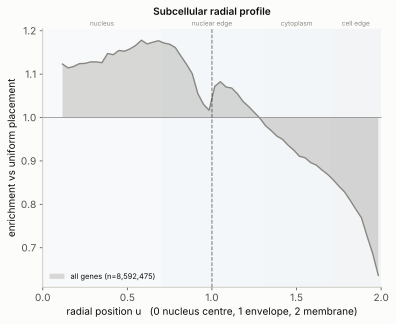

In [4]:
ab.pl.subcellular_profile(mdata, coords).show()

The grey curve is the whole panel. Where it departs from 1.0, transcripts *in general* depart from
uniform placement — and that is a mix of three things you cannot separate here: real nuclear
retention, the fact that a 2-D image of a 3-D cell is centre-weighted, and segmentation truncation at
the cell edge.

That is exactly why the headline test in section 5 compares each gene against **the other transcripts
of the same cell** rather than against uniform placement. Anything acting on all genes alike — the
projection, the truncation, the segmentation — cancels in that comparison. Keep this grey curve in
mind as the thing a gene has to beat.

## 4. Named compartments

Cuts on `u` give four compartments, using the vocabulary the field reads: `nucleus`, `nuclear_edge`,
`cytoplasm`, `cell_edge` (Bento's classes, minus its supervised `none`). The default cuts sit
symmetrically about the envelope; `compartment_mode='metric'` replaces them with bands defined by
physical distance to each membrane, which is preferable when the cytoplasm is thick enough to support
it.

Use both representations: the continuous `u` carries the gradient, the compartments make it sayable.

## 5. Which genes are localized?

`tl.subcellular_enrichment` returns **one row per gene**. Two layers, answering two different
questions.

**Layer 1 — `p_adj_omnibus`, `cmh_log_or_*`. Filter on this.** A Cochran-Mantel-Haenszel test
stratified by cell: does gene *g* occupy this compartment more than the other transcripts *of the same
cell*? Because the comparison happens inside each cell, everything that varies between cells but not
between genes cancels — the projection geometry, segmentation error, section thickness, cell size, how
crowded the optics were. The effect size is a Mantel-Haenszel log odds ratio with a
Robins-Breslow-Greenland standard error.

**Layer 2 — `median_d`, `p_adj_berman`. Absolute, and often out of reach.** Berman's `Z1` on `v` per
cell, aggregated across cells by a Wilcoxon signed-rank test. Because `v` has null mean exactly `1/2`
and variance exactly `1/12` in every cell, the per-cell statistic needs no weighting. This makes a
genuinely absolute statement — and therefore it *does* carry the projection bias. It also needs
several copies of the gene in each of many cells, which a few-hundred-plex panel at tens of
transcripts per cell does not provide for most genes. Expect `NaN` here for most rows; that is the
data being honest.

`shape_ks` / `p_shape` compare a gene's whole `v` distribution against the rest of the panel's. Its
replication unit is the transcript, so at this scale it rejects for nearly everything — it is there to
see distribution *shapes* (a mid-cytoplasmic ring, say) that the mean-based layers cannot, and it is a
descriptor rather than inference.

In [5]:
res = ab.tl.subcellular_enrichment(mdata, coords)

sig = res[res['p_adj_omnibus'] < 0.05].copy()
sig['axis'] = sig['cmh_log_or_cell_edge'] - sig['cmh_log_or_nucleus']
print(f"{len(sig)} / {len(res)} genes localized (p_adj_omnibus < 0.05)")

cols = ['gene', 'n_transcripts', 'n_cells', 'cmh_log_or_nucleus',
        'cmh_log_or_cell_edge', 'median_d', 'p_adj_berman']
well = sig[sig['n_transcripts'] >= 10_000]
print("\nmost membrane-biased (well-powered genes):")
print(well.nlargest(8, 'axis')[cols].round(3).to_string(index=False))
print("\nmost nucleus-biased:")
print(well.nsmallest(8, 'axis')[cols].round(3).to_string(index=False))

INFO:astrolabe.tl._subcellular:subcellular_enrichment: 380 rows tested; 363 localized at p_adj_omnibus<0.05 (cell-stratified CMH, the headline test). Layer 2 (absolute, per-cell) reached 287 row(s) -- the rest lack 3+ copies of the gene in 20+ cells -> uns['subcellular_enrichment']


363 / 380 genes localized (p_adj_omnibus < 0.05)

most membrane-biased (well-powered genes):
     gene  n_transcripts  n_cells  cmh_log_or_nucleus  cmh_log_or_cell_edge  median_d  p_adj_berman
     GPX2          12520    10683              -0.756                 0.396     0.197         0.000
     MALL         443262    88669              -0.716                 0.401     0.178         0.000
    GNG11          48633    32877              -0.658                 0.381     0.198         0.000
    SFTA2          78888    45573              -0.634                 0.383     0.183         0.000
    ACTG2          61100    44103              -0.626                 0.333     0.139         0.000
MTRNR2L11          20068    17134              -0.618                 0.335     0.080         0.002
  SCGB2A1          33341    21975              -0.552                 0.369     0.156         0.000
   CAVIN1          53476    36992              -0.501                 0.413     0.070         0.000

most n

### Two things to check before believing a row

**Effect size, not just significance.** With millions of transcripts almost everything is
"significant"; `p_adj_omnibus` tells you the effect is not zero, and `cmh_log_or_*` tells you whether
it is worth caring about.

**Abundance.** On most panels the odds ratio correlates with how abundant a gene is, in a particular
direction: rarer genes look more nuclear. There is a mechanism for that — nuclear export is a rate,
not a switch, so a gene with few mature cytoplasmic copies has a larger *fraction* of its molecules
still in the nucleus. That is real biology, not something to correct away. But it does mean a
barely-detected gene topping the ranking may be telling you about its abundance rather than its
localization, which is why `abundance_rank` is in the table and why the figures below carry a
transcript-count floor.

In [6]:
from scipy.stats import spearmanr

for c in ('cmh_log_or_nucleus', 'cmh_log_or_cell_edge'):
    m = np.isfinite(res[c])
    rho = spearmanr(res.loc[m, c], res.loc[m, 'n_transcripts']).statistic
    print(f"spearman({c}, n_transcripts) = {rho:+.3f}")

spearman(cmh_log_or_nucleus, n_transcripts) = -0.613
spearman(cmh_log_or_cell_edge, n_transcripts) = +0.655


## 6. The localization landscape

Four named columns, so there is nothing to decode. Three things about how this figure picks and scales
its rows, because each one changes what you would conclude:

- **Rows come from both tails.** Half are the most nucleus-biased genes, half the most
  membrane-biased, ordered along that contrast. Ranking by *absolute* effect instead would fill the
  figure from whichever tail is stronger — usually the nuclear one — and every row would look alike.
- **`min_transcripts` sets a power floor**, so a gene with a few hundred detections cannot lead.
- **Colour limits are a robust percentile**, so one extreme cell cannot flatten everything else to the
  midpoint.

Rings mark the cells that *fail* the per-compartment test — at this scale almost everything passes, so
the exceptions are the informative marks. Transcript counts are printed beside each gene.

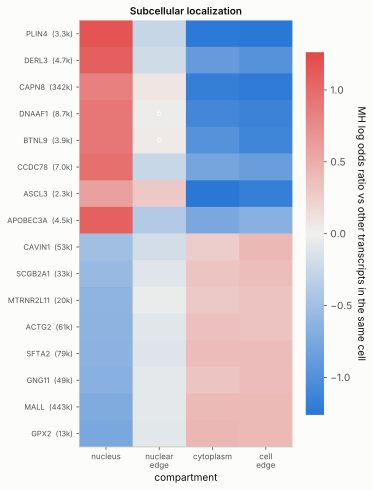

In [7]:
ab.pl.subcellular_enrichment_plot(mdata, res, n_top=16).show()

Read it as two blocks. The membrane-biased block should be recognisable: mRNAs for membrane,
cytoskeletal and secreted proteins are translated near where the protein is needed, so their
transcripts sit at the periphery. If a panel returns a peripheral block full of cytoskeletal and
secretory genes, that is the method agreeing with cell biology nobody told it about — the strongest
evidence available that the coordinate means what it claims.

The two tails are rarely symmetric in size. A stronger nuclear tail than peripheral tail is common,
and is partly the abundance relation from section 5.

### Is the signal gene-specific, or one pattern repeated?

A useful sanity check on any gene x compartment matrix. Decompose its variance into a compartment main
effect (the same pattern in every gene), a gene main effect (some genes just shifted), and the
interaction — which is the only part that answers "does this gene localize differently from that one".

In [8]:
L = res[[f'log2_vs_pooled_{c}' for c in compartments]].to_numpy()
tot = L.var()
dm, gm = L.mean(axis=0), L.mean(axis=1)
resid = L - dm[None, :] - gm[:, None] + L.mean()
print("variance of log2(observed / pooled):")
print(f"  compartment main effect (shared by all genes) : {100*dm.var()/tot:5.1f}%")
print(f"  gene main effect                             : {100*gm.var()/tot:5.1f}%")
print(f"  gene x compartment (the actual signal)       : {100*resid.var()/tot:5.1f}%")

C_ = np.corrcoef(L - L.mean(axis=1, keepdims=True))
iu = np.triu_indices(len(L), 1)
print(f"  median correlation between gene patterns     : {np.median(C_[iu]):.3f}")

variance of log2(observed / pooled):
  compartment main effect (shared by all genes) :  13.8%
  gene main effect                             :  13.3%
  gene x compartment (the actual signal)       :  72.8%
  median correlation between gene patterns     : 0.173


The interaction should dominate and the median between-gene correlation should be low. If instead the
compartment main effect dominates, the figure is one pattern rescaled per gene — and whatever produces
it is shared by every gene, so it is a property of the assay or the coordinate rather than of any gene.

## 7. Radial profiles for individual genes

The table says which genes and how much; the profile says *what shape*. Read the shape, not just the
direction: a gene displaced smoothly toward the membrane looks different from one piled into a thin
rim, and different again from one with both a nuclear and a membrane population — and all three can
share the same mean.

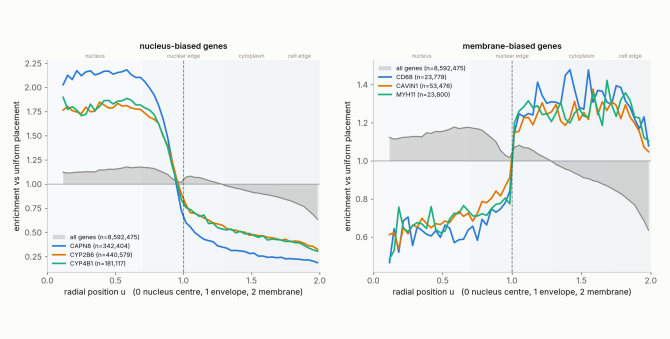

In [9]:
nuclear = ['CAPN8', 'CYP2B6', 'CYP4B1']
peripheral = ['CD68', 'CAVIN1', 'MYH11']

(ab.pl.subcellular_profile(mdata, coords, genes=nuclear,
                           title='nucleus-biased genes')
 | ab.pl.subcellular_profile(mdata, coords, genes=peripheral,
                             title='membrane-biased genes')
 ).show()

## 8. Checking the test is calibrated on your data

Everything above rests on the test being calibrated. You can check that directly, and you should — the
check is cheap and it is specific to your dataset rather than to a benchmark someone else ran.

**Permute the gene labels within each cell.** This keeps every cell's geometry, every cell's total
count, every gene's abundance, and the entire spatial point pattern exactly as they were. It destroys
only the association between gene identity and position, which is precisely what the test claims to
measure. A calibrated test returns essentially nothing.

Negative-control probes are the other natural check. Run the cell below to see whether they are usable
on your panel — usually they carry too few detections to be tested at all, which is worth knowing
rather than assuming.

In [10]:
ctrl = xen.var['is_control_probe'].to_numpy()
ctrl_names = set(xen.var_names[ctrl])
n_ctrl_tx = int(coords['gene'].isin(ctrl_names).sum())
print(f"{int(ctrl.sum())} control probes carry {n_ctrl_tx} of {len(coords)} "
      f"assigned transcripts ({100 * n_ctrl_tx / len(coords):.4f}%)")
print(f"of those, {int(res['gene'].isin(ctrl_names).sum())} clear "
      f"min_gene_transcripts and appear in the result table")

164 control probes carry 1182 of 8592475 assigned transcripts (0.0138%)
of those, 3 clear min_gene_transcripts and appear in the result table


In [11]:
import pandas as pd

rng = np.random.default_rng(0)
cell_codes = coords['cell_id'].cat.codes.to_numpy()
gene_codes = coords['gene'].cat.codes.to_numpy()

# Two orderings that group rows by cell identically: one keeps the original
# within-cell order, one randomizes it. Reading labels through the second and
# writing them through the first permutes strictly within each cell.
by_cell = np.argsort(cell_codes, kind='stable')
randomized = np.lexsort((rng.random(len(cell_codes)), cell_codes))

shuffled = gene_codes.copy()
shuffled[by_cell] = gene_codes[randomized]

perm = coords.copy()
perm['gene'] = pd.Categorical.from_codes(shuffled, coords['gene'].cat.categories)
assert (perm['gene'].value_counts() == coords['gene'].value_counts()).all()

res_perm = ab.tl.subcellular_enrichment(mdata, perm)
print(f"real data : {int((res['p_adj_omnibus'] < 0.05).sum())} / {len(res)} localized")
print(f"permuted  : {int((res_perm['p_adj_omnibus'] < 0.05).sum())} / {len(res_perm)} localized")
print(f"\nlargest |MH log OR| for nucleus   real {res['cmh_log_or_nucleus'].abs().max():.3f}"
      f"   permuted {res_perm['cmh_log_or_nucleus'].abs().max():.3f}")

INFO:astrolabe.tl._subcellular:subcellular_enrichment: 380 rows tested; 0 localized at p_adj_omnibus<0.05 (cell-stratified CMH, the headline test). Layer 2 (absolute, per-cell) reached 287 row(s) -- the rest lack 3+ copies of the gene in 20+ cells -> uns['subcellular_enrichment']


real data : 363 / 380 localized
permuted  : 0 / 380 localized

largest |MH log OR| for nucleus   real 1.344   permuted 0.328


## 9. The raw evidence

Tables and densities are summaries; this is what they summarize. Both outlines are drawn — without the
nucleus there is no way to check whether a "nuclear" call is actually nuclear.

The full section first, so the crop has somewhere to be. A 600 µm box is large enough to see against a
section several millimetres across, and the crop inside it small enough to resolve single cells; one
box cannot do both jobs.

In [12]:
coords_xy = xen.obsm['spatial']
cx = float(np.median(coords_xy[:, 0]))
cy = float(np.median(coords_xy[:, 1]))

context_rect = ab.pl.rectangle((cx - 300, cy - 300), 600.0, 600.0)
zoom_rect = ab.pl.rectangle((cx - 60, cy - 60), 120.0, 120.0)

context = ab.pp.crop(mdata, context_rect, inplace=False)
zoom = ab.pp.crop(mdata, zoom_rect, inplace=False)
print(f"context crop: {context['xenium'].n_obs} cells; zoom crop: {zoom['xenium'].n_obs} cells")

(
    (ab.pl.boundaries(mdata, color='leiden', title='whole section')
     + ab.pl.annotation(context_rect))
    | (ab.pl.boundaries(context, color='leiden', title='600 µm context')
       + ab.pl.annotation(zoom_rect))
).show()

INFO:astrolabe.pp._transform:crop: xenium: keeping 3675 / 154376 cells inside region.
INFO:astrolabe.pp._transform:crop: xenium: keeping 119 / 154376 cells inside region.


context crop: 3675 cells; zoom crop: 119 cells


Now at single-transcript resolution. Left: every gene, which shows the *geometry* — the radial layering
of the compartments, following each cell's own shape. Right: one gene, which is where localization
becomes visible cell by cell.

In [13]:
(ab.pl.subcellular_plot(zoom, coords, title='all genes — the geometry')
 | ab.pl.subcellular_plot(zoom, coords, genes=['CAPN8'],
                          title='CAPN8 — nucleus-biased')
 ).show()

## 10. Per-cell indices

Everything so far is gene-centric. For a *cell*-centric readout, `tl.subcellular_indices` computes the
three indices of Stueland et al. (2019), each a ratio against the same moment of a uniform fill of that
cell's own mask:

- **PDI** — second moment about the **nucleus centroid** over the mask's. `1` diffuse, `< 1`
  perinuclear, `> 1` peripheral.
- **DI** — the same about the **RNA centroid**. `< 1` means concentrated somewhere, anywhere.
- **PI** — distance from the RNA centroid to the cell centroid, in units of the mask's radius of
  gyration. Grows with polarization.

plus `rdi = mean(v)`, which is `0.5` under uniform placement by construction.

**Map `rdi_shrunk`, not `rdi_z`.** The standardized index has null variance `1/n`, so a raw map paints
every low-count cell as an extreme value — a volcano-shaped map that looks like regional biology and is
sampling noise. The shrunk column applies random-effects shrinkage, and `uns` stores both variance
components so you can see how much of the map is real.

In [14]:
ab.tl.subcellular_indices(mdata, coords)

ix = xen.uns['subcellular_indices']
print(f"between-cell variance tau2 = {ix['tau2']:.4f}")
print(f"sampling noise  mean(1/n)  = {ix['mean_inv_n']:.4f}")
print(f"shrinkage factor           = {ix['tau2'] / (ix['tau2'] + ix['mean_inv_n']):.2f}")
print(f"cells scored {ix['n_cells']}, excluded below "
      f"{ix['min_cell_transcripts']} transcripts: {ix['n_excluded']}")

for k in ('rdi', 'rdi_shrunk', 'pdi', 'di', 'pi'):
    print(f"  {k:<11s} median {np.nanmedian(xen.obs['subcellular_' + k]):+.3f}")

INFO:astrolabe.tl._subcellular:subcellular_indices: 109218 cells scored (39881 excluded below 30 transcripts); between-cell variance tau2=0.0222 vs sampling noise mean(1/n)=0.0177 -> obs['subcellular_rdi_shrunk'], obs['subcellular_pdi'], obs['subcellular_di'], obs['subcellular_pi']


between-cell variance tau2 = 0.0222
sampling noise  mean(1/n)  = 0.0177
shrinkage factor           = 0.56
cells scored 109218, excluded below 30 transcripts: 39881
  rdi         median +0.453
  rdi_shrunk  median -0.094
  pdi         median +0.904
  di          median +0.869
  pi          median +0.133


Compare the two variance components before reading the map. If `tau2` is comparable to `mean(1/n)`,
roughly half of what you see in the unshrunk index is noise, and the shrinkage factor says how much of
each cell's deviation survives. If `tau2` comes out at zero, the honest conclusion is that there is no
between-cell variation to map — which is a result, provided you say it that way rather than showing a
flat figure and calling it biology.

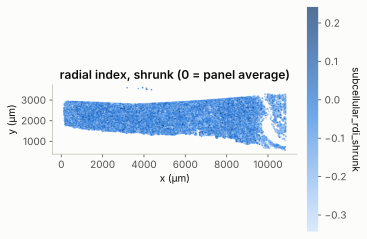

In [15]:
# This section is a long thin strip, so each map gets its own cell. Composing two
# of them -- with either '|' or '/' -- letterboxes both into slivers, because
# PlotGrid gives every panel a square cell by design.
ab.pl.points(mdata, color='subcellular_rdi_shrunk',
             title='radial index, shrunk (0 = panel average)').show()

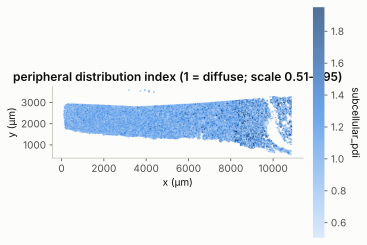

In [16]:
# PDI has a long right tail, so clip the colour scale to percentiles -- otherwise
# a handful of extreme cells wash the whole map out
plo, phi = np.nanpercentile(xen.obs['subcellular_pdi'], [2, 98])
ab.pl.points(mdata, color='subcellular_pdi', vmin=plo, vmax=phi,
             title=f'peripheral distribution index '
                   f'(1 = diffuse; scale {plo:.2f}-{phi:.2f})').show()

## 11. Localization is cell-type-specific

Pooling every cell asks "is this gene localized in this tissue". Usually the question is narrower.
Localization programs differ by lineage, and a gene that is peripheral in epithelium and nuclear in
immune cells *cancels* when the two are pooled — the pooled answer is not a weaker version of the
truth, it is a different and possibly empty one.

`groupby=` runs the whole analysis within each group: the pooled reference becomes the group's own
transcripts, and the strata its own cells.

In [17]:
coords_ct = ab.tl.subcellular_coords(mdata, groupby='leiden')
res_ct = ab.tl.subcellular_enrichment(mdata, coords_ct, groupby='leiden')

wide = res_ct.pivot(index='gene', columns='group', values='cmh_log_or_cell_edge')

# Rank only genes with a finite effect AND real depth in enough clusters. A gene
# confined to (or absent from) a compartment in one cluster has an infinite odds
# ratio there, which would win any spread ranking without describing a contrast;
# and a cluster holding a few dozen transcripts of the gene gives an effect that
# is mostly sampling noise, which would win it for the same empty reason.
MIN_TX = 1500
depth = res_ct.pivot(index='gene', columns='group', values='n_transcripts')
finite = wide.replace([np.inf, -np.inf], np.nan).where(depth >= MIN_TX)
enough = finite.notna().sum(axis=1) >= 5
finite = finite[enough]
spread = (finite.max(axis=1) - finite.min(axis=1)).sort_values(ascending=False)

print(f"{int(enough.sum())} / {len(wide)} genes have a finite effect and "
      f">= {MIN_TX} transcripts in >= 5 clusters")
print()
print("of those, the ones whose cell-edge effect varies most between clusters:")
print(spread.head(8).round(3).to_string())

top = spread.index[0]
print()
print(f"{top} per cluster:")
print(finite.loc[top].round(3).to_string())

INFO:astrolabe._utils:subcellular_coords: using uns['transcripts'], which has been pruned by a filtering step (rows of removed cells/genes dropped).
INFO:astrolabe.tl._subcellular:subcellular: repaired 179 cell and 8037 nucleus ring(s) via make_valid
INFO:astrolabe.tl._subcellular:subcellular_coords: 1423803 transcript(s) reference a cell id absent from obs_names and were dropped
INFO:astrolabe.tl._subcellular:subcellular_coords: 354462 transcript(s) (4.0%) fall outside their own cell polygon and were dropped -- assignment/segmentation disagreement
INFO:astrolabe.tl._subcellular:subcellular_coords: 8592475 transcripts in 149099 cells; pooled occupancy nucleus=0.233, nuclear_edge=0.425, cytoplasm=0.183, cell_edge=0.159 -> obs['subcellular_n_transcripts'], obsm['subcellular_compartment_fractions'], uns['subcellular']
INFO:astrolabe.tl._subcellular:subcellular_enrichment: 2545 rows tested across 9 group(s); 1707 localized at p_adj_omnibus<0.05 (cell-stratified CMH, the headline test). Lay

59 / 378 genes have a finite effect and >= 1500 transcripts in >= 5 clusters

of those, the ones whose cell-edge effect varies most between clusters:
gene
CD163     1.081
CYP2B6    0.981
CTSK      0.978
CXCR4     0.810
CYP4B1    0.779
MRC1      0.730
DST       0.719
CD34      0.709

CD163 per cluster:
group
0    0.362
1    0.161
2      NaN
3   -0.719
4    0.170
5    0.258
6      NaN
7      NaN
8      NaN


CD163: lowest in cluster 3 (-0.72), highest in cluster 0 (+0.36)


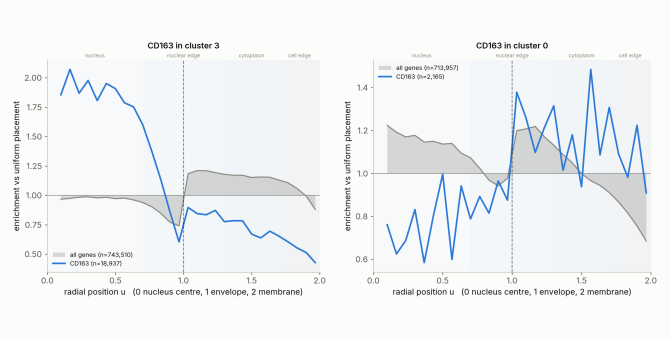

In [18]:
ranked = finite.loc[top].dropna().sort_values()
lo, hi = str(ranked.index[0]), str(ranked.index[-1])
print(f"{top}: lowest in cluster {lo} ({ranked.iloc[0]:+.2f}), "
      f"highest in cluster {hi} ({ranked.iloc[-1]:+.2f})")

# fewer bins than the pooled figure: a per-cluster curve has a fraction of the
# transcripts, and 60 bins over a few thousand of them is mostly bin noise
(ab.pl.subcellular_profile(mdata, coords_ct, genes=[top], group=lo, n_bins=30,
                           title=f'{top} in cluster {lo}')
 | ab.pl.subcellular_profile(mdata, coords_ct, genes=[top], group=hi, n_bins=30,
                             title=f'{top} in cluster {hi}')
 ).show()

## 12. The other question: compositional domains

Everything so far partitions the cell by *geometry* and asks where a gene sits in it. The complementary
question is whether the cell interior decomposes into recurring **molecular neighbourhoods** — a
perinuclear ER-like zone, a secretory pole — that no geometric partition names. That is what `tl.flux`
and `tl.fluxmap` do (Bento's RNAflux): at every interior pixel, take the local gene composition,
subtract the cell's own overall composition, reduce, then quantize the result into domains with a SOM.

The obstacle on a targeted panel is arithmetic. A composition needs enough transcripts in a
*subcellular* neighbourhood to be a composition rather than a one-hot, and a few-hundred-plex panel at
tens of transcripts per cell gives a neighbourhood of about five. Check the numbers on your own data
first:

In [19]:
from scipy.spatial import cKDTree

tx_tbl = xen.uns['transcripts']
P = np.column_stack([tx_tbl['x_location'].to_numpy(), tx_tbl['y_location'].to_numpy()])
tree = cKDTree(P)
mean_cell_radius = float(np.nanmean(np.sqrt(xen.obs['cell_area'] / np.pi)))

probe = P[rng.choice(len(P), 4000, replace=False)]
print(f"panel: {xen.n_vars} features; mean cell radius {mean_cell_radius:.2f} µm")
print()
print(f"{'radius':>10s} {'mean transcripts':>18s} {'vs panel size':>15s}")
for r in (mean_cell_radius / 3, 2.5, 5.0, mean_cell_radius):
    n = np.fromiter((len(i) for i in tree.query_ball_point(probe, r)),
                    dtype=int, count=len(probe))
    print(f"{r:>9.2f}µm {n.mean():>18.1f} {n.mean() / xen.n_vars:>14.1%}")

panel: 541 features; mean cell radius 4.55 µm

    radius   mean transcripts   vs panel size
     1.52µm                7.2           1.3%
     2.50µm               17.5           3.2%
     5.00µm               63.8          11.8%
     4.55µm               53.4           9.9%


A few transcripts spread over several hundred genes is a one-hot, and decomposing it returns components
of sampling noise. `tl.flux` measures this and refuses rather than handing you domains it cannot
support:

In [20]:
try:
    ab.tl.flux(mdata, sigma_um=2.5)
except ValueError as err:
    print(str(err))

INFO:astrolabe._utils:flux: using uns['transcripts'], which has been pruned by a filtering step (rows of removed cells/genes dropped).
INFO:astrolabe.tl._subcellular:subcellular: repaired 179 cell and 8037 nucleus ring(s) via make_valid
INFO:astrolabe.tl._flux:flux: 8946937 transcripts over 526 gene group(s) (from 526 genes) in 149099 cells; sigma=2.50 um (mean cell radius 4.58 um), prior_strength=5.0


flux: the median neighbourhood holds 0.051 effective transcripts per composition group (26.9 spread over 526 groups) at sigma=2.50 um, estimated on a random sample of 200 cells. That is too little evidence to estimate a composition -- the vector is closer to a one-hot than to a proportion, and the decomposition below would return components of sampling noise. Options, in order: pass gene_groups= (e.g. 'som_gene_module') to reduce the composition space, which is by far the most effective; raise sigma_um; or use ab.tl.subcellular_coords/subcellular_enrichment, which needs no local composition at all. Pass force=True to run anyway.


### Reducing the composition space

The fix is to stop asking for a several-hundred-way composition. A dozen co-expression modules is a
space a twenty-transcript neighbourhood *can* estimate, and `tl.som_gene_modules` produces exactly that
labelling. `gene_groups=` takes either a `var` column name or an explicit `{gene: group}` mapping;
the mapping is used here so the modules can be fitted on the gene-expression features alone.

Two smaller helps come with it: a Gaussian kernel (`sigma_um`) instead of a hard disc, so the reported
neighbourhood size is the *effective* one; and shrinkage toward each cell's own composition
(`prior_strength`), so a pixel with little evidence returns the cell mean and contributes nothing
rather than contributing noise.

Expect a large `unassigned` class. On a targeted panel most genes were chosen as independent markers,
so most of them correlate with nothing in particular; `tl.som_gene_modules` collects them into a
residual class (WGCNA's grey module) rather than reporting them as programs, and `flux` carries that
class as one explicit "other" category instead of folding it in silently. It is a real ceiling on how
finely this method can resolve composition here, not a setting to tune away.

**This is priced per pixel** — every interior pixel of every cell is a neighbourhood query — so it runs
on a small region. A 300 µm box takes a couple of minutes; a whole section is hours.

In [21]:
# fit the modules on the gene-expression features only: control probes have no
# co-expression structure to find, so they would only enlarge the residual class.
# score_cells=False because only the gene labels are needed here.
real = xen[:, ~xen.var['is_control_probe'].to_numpy()].copy()
ab.tl.som_gene_modules(real, n_modules=10, seed=42, score_cells=False)
modules = real.var['som_gene_module'].astype(str).to_dict()
print(pd.Series(modules).value_counts().to_string())

flux_rect = ab.pl.rectangle((cx - 150, cy - 150), 300.0, 300.0)
region = ab.pp.crop(mdata, flux_rect, inplace=False)

emb = ab.tl.flux(region, gene_groups=modules, sigma_um=2.5, points_per_cell=120)
print()
print(f"{len(emb)} pixels; effective neighbourhood size "
      f"median {emb['n_eff'].median():.1f}, "
      f"IQR {emb['n_eff'].quantile(0.25):.1f}-{emb['n_eff'].quantile(0.75):.1f}")

INFO:astrolabe.tl._som:som_gene_modules: training 10×10 grid on 377 genes (z-scored, 50 dims, 50 epochs, sigma=2.50→1) → 10 modules
INFO:astrolabe.tl._som:som_gene_modules: 377 genes → 7 coherent module(s) + 175 unassigned (QE=145.536, TE=0.011; PCA retained 26% of variance, distance fidelity 0.47) → var['som_gene_module'], var['som_gene_module_kme'], uns['som_gene_modules']['module_coherence']


unassigned    175
M2             46
M0             44
M4             32
M5             26
M6             26
M8             14
M7             14


INFO:astrolabe.pp._transform:crop: xenium: keeping 859 / 154376 cells inside region.
INFO:astrolabe._utils:flux: using uns['transcripts'], which has been pruned by a filtering step (rows of removed cells/genes dropped).
INFO:astrolabe.tl._subcellular:subcellular: repaired 1 cell and 84 nucleus ring(s) via make_valid
INFO:astrolabe.tl._flux:flux: 63877 transcripts over 8 gene group(s) (from 380 genes) in 804 cells; sigma=2.50 um (mean cell radius 4.89 um), prior_strength=5.0
INFO:astrolabe.tl._flux:flux: 96908 pixels x 7 components; median effective neighbourhood 33.9 transcripts over 8 group(s) (4.2 per group), SVD retained 100.0% -> uns['flux']



96908 pixels; effective neighbourhood size median 33.9, IQR 24.2-45.3


In [22]:
dom = ab.tl.fluxmap(region, emb, n_domains=3, seed=0)
print(dom['domain'].value_counts().to_string())

ctx = region['xenium']
print()
print("mean domain occupancy per cell:")
for i, name in enumerate(ctx.uns['fluxmap']['domain_names']):
    print(f"  {name}: {np.nanmean(ctx.obsm['fluxmap_fractions'][:, i]):.3f}")

INFO:astrolabe.tl._flux:fluxmap: training 30x30 grid on 96908 of 96908 pixels (7 dims, 10 epochs) -> 3 domains
INFO:astrolabe.tl._flux:fluxmap: 3 domains over 96908 pixels (QE=1.062, TE=0.061) -> obsm['fluxmap_fractions'], uns['fluxmap']


domain
fluxmap1      63959
fluxmap2      23723
fluxmap3       9226
background        0

mean domain occupancy per cell:
  fluxmap1: 0.660
  fluxmap2: 0.245
  fluxmap3: 0.095


### Looking at them

Domains are per-pixel labels dissolved into one polygon per cell per domain, in
`obsm['fluxmap{i}_boundaries']`. At section scale they are invisible, so zoom until single cells fill
the frame — this is subcellular structure, and it has to be looked at from a few tens of microns away.

INFO:astrolabe.pp._transform:crop: xenium: keeping 26 / 859 cells inside region.


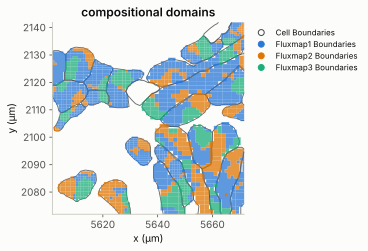

In [23]:
dom_rect = ab.pl.rectangle((cx - 35, cy - 35), 70.0, 70.0)
close = ab.pp.crop(region, dom_rect, inplace=False)

names = ctx.uns['fluxmap']['domain_names']
shades = ab.pl.get_theme().cat_core


def domain_panel(obj, key, title):
    # color= takes a literal colour as well as a field name; na_color would not
    # work here, since it only covers missing values of a categorical field
    out = ab.pl.boundaries(obj, color='#40464d', linewidth=0.9, title=title)
    for i in range(len(names)):
        out = out + ab.pl.boundaries(
            obj, boundaries_key=f'{key}{i + 1}_boundaries',
            color=shades[i], linewidth=0.0, fill_alpha=0.75)
    return out


domain_panel(close, 'fluxmap', 'compositional domains').show()

### The same calibration check, applied to domains

A SOM will always return domains — that is what quantization does. So the question is not whether
domains appear but whether they survive destroying the gene-position association, exactly as in
section 8. Shuffle gene labels within each cell and compare the partitions: if the permuted run
reproduces the real one, the domains are a property of the decomposition rather than of the tissue.

In [24]:
from sklearn.metrics import adjusted_rand_score

ctx_tx = ctx.uns['transcripts'].to_pandas()   # a pyarrow Table
cc = pd.Categorical(ctx_tx['cell_id'].astype(str)).codes.astype(np.int64)
gg = ctx_tx['feature_name'].to_numpy()
by_cell = np.argsort(cc, kind='stable')
randomized = np.lexsort((rng.random(len(cc)), cc))
shuf = gg.copy()
shuf[by_cell] = gg[randomized]
ctx_tx['feature_name'] = shuf

emb_p = ab.tl.flux(region, ctx_tx, gene_groups=modules, sigma_um=2.5,
                   points_per_cell=120, key_added='flux_perm')
dom_p = ab.tl.fluxmap(region, emb_p, n_domains=3, seed=0,
                      key_added='fluxmap_perm')
dom_b = ab.tl.fluxmap(region, emb, n_domains=3, seed=1, polygons=False,
                      key_added='fluxmap_seed1')

a = dom['domain'].astype(str)
print("agreement between domain partitions:")
print(f"  real seed 0 vs real seed 1 : "
      f"{adjusted_rand_score(a, dom_b['domain'].astype(str)):.3f}")
print(f"  real seed 0 vs permuted    : "
      f"{adjusted_rand_score(a, dom_p['domain'].astype(str)):.3f}")

INFO:astrolabe.tl._subcellular:subcellular: repaired 1 cell and 84 nucleus ring(s) via make_valid
INFO:astrolabe.tl._flux:flux: 63877 transcripts over 8 gene group(s) (from 380 genes) in 804 cells; sigma=2.50 um (mean cell radius 4.89 um), prior_strength=5.0
INFO:astrolabe.tl._flux:flux: 96908 pixels x 7 components; median effective neighbourhood 33.9 transcripts over 8 group(s) (4.2 per group), SVD retained 100.0% -> uns['flux_perm']
INFO:astrolabe.tl._flux:fluxmap: training 30x30 grid on 96908 of 96908 pixels (7 dims, 10 epochs) -> 3 domains
INFO:astrolabe.tl._flux:fluxmap: 3 domains over 96908 pixels (QE=1.147, TE=0.063) -> obsm['fluxmap_perm_fractions'], uns['fluxmap_perm']
INFO:astrolabe.tl._flux:fluxmap: training 30x30 grid on 96908 of 96908 pixels (7 dims, 10 epochs) -> 3 domains
INFO:astrolabe.tl._flux:fluxmap: 3 domains over 96908 pixels (QE=1.072, TE=0.060) -> obsm['fluxmap_seed1_fractions'], uns['fluxmap_seed1']


agreement between domain partitions:
  real seed 0 vs real seed 1 : 0.206
  real seed 0 vs permuted    : 0.027


INFO:astrolabe.pp._transform:crop: xenium: keeping 26 / 859 cells inside region.


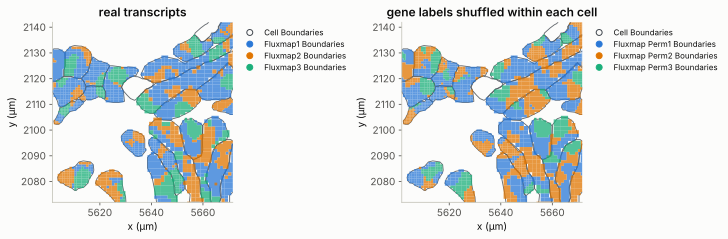

In [25]:
close_p = ab.pp.crop(region, dom_rect, inplace=False)

(domain_panel(close, 'fluxmap', 'real transcripts')
 | domain_panel(close_p, 'fluxmap_perm', 'gene labels shuffled within each cell')
 ).show()

Read those two numbers together, and read them strictly.

Agreement with the permuted run is what says the domains are not an artifact of the decomposition; it
should be near zero, and on this panel it is. **Seed-to-seed agreement is the one that limits what you
may claim**, and on a 380-gene panel it comes out low — around 0.2, meaning two runs of the same
method on the same data agree on the broad picture and disagree on most boundaries. Treat a low-plex
domain map as a *detection* that compositional structure exists, never as a segmentation you can
measure per cell. If you need the second thing, you need a panel with an order of magnitude more genes.

Two more caveats worth carrying. The permuted ARI is small but not exactly zero, and it never will be:
shuffling gene labels leaves each pixel's *evidence* untouched, and a pixel with few transcripts
shrinks toward its cell mean whatever its labels are — so a little of any domain map tracks how much
evidence each pixel had rather than what was in it. And domains are numbered by size, not matched
across runs, so compare partitions with ARI as above rather than by domain name.

## Summary

- `tl.subcellular_coords` — the coordinate `u ∈ [0, 2]` from the real cell and nucleus polygons, its
  per-cell probability-integral transform `v`, named compartments, and a bearing in the
  nucleus-anchored polarity frame.
- `tl.subcellular_enrichment` — one row per gene. **Filter on `p_adj_omnibus`** and read
  `cmh_log_or_*` as the effect size; Layer 2 (`median_d`, `p_adj_berman`) is absolute and needs
  per-cell depth most targeted panels lack. Pass `groupby=` whenever cell types differ.
- `tl.subcellular_indices` — Stueland's PDI / DI / PI plus a shrunk radial index. Map the shrunk one.
- `pl.subcellular_profile` (default `reference='null'`, so uniform placement is a flat line at 1.0) /
  `pl.subcellular_enrichment_plot` / `pl.subcellular_plot`.
- `tl.flux` / `tl.fluxmap` — compositional rather than geometric domains. Pass `gene_groups=` on a
  targeted panel; it refuses to run when the neighbourhood cannot support a composition.

**Checks worth running on your own data**, in the order they will save you time: the shell thickness
(is there cytoplasm to resolve?), the variance decomposition (is the signal gene-specific?), the label
permutation (does the test return nothing when there is nothing?), and `abundance_rank` (is this
finding separable from expression level?).

**Where to go next:** `13_self_organizing_maps.ipynb` for SOM-based cell states and gene modules;
`10_gradient_and_flux.ipynb` for directionality at the *tissue* scale rather than inside cells;
`03_neighborhood_analysis.ipynb` to relate these per-cell indices to neighbourhood composition.